# ECC 3D Scene Ray Tracing and OFDM BER Simulation

This notebook builds a 3D scene around Ewha Campus Complex (ECC) from OpenStreetMap building data, computes a multipath channel with Sionna RT, and analyzes OFDM-QPSK bit error rate (BER).

**Workflow**: OSM building data → 3D mesh → Sionna ray tracing → CIR → OFDM/QPSK → BER

> Package installation and environment setup are documented in the README. Run this notebook from the project root.

In [1]:
# Imports and reproducibility
import os

import matplotlib.pyplot as plt
import mitsuba as mi
import numpy as np
import osmnx as ox
import pandas as pd
import sionna
import torch
import trimesh
from scipy.special import erfc
from shapely.geometry import Polygon, Polygon as ShapelyPolygon
from sionna.rt import (Camera, PathSolver, PlanarArray, RadioMapSolver,
                       Receiver, Transmitter, load_scene)

RNG_SEED = 42
np.random.seed(RNG_SEED)

print("Sionna version :", sionna.__version__)
print("PyTorch version :", torch.__version__)
print("GPU available :", torch.cuda.is_available())
print("GPU name :", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "N/A")
print("Mitsuba variant:", mi.variant())

Sionna version : 2.0.1
PyTorch version : 2.9.1+cu126
GPU available : True
GPU name : NVIDIA GeForce RTX 4090
Mitsuba variant: cuda_ad_mono_polarized


## 1. Build the ECC 3D Scene

This section retrieves OpenStreetMap building footprints and creates the 3D meshes and Sionna RT scene.

### 1.1 Download OSM Building Footprints

In [2]:
LAT_CENTER = 37.56101
LON_CENTER = 126.94614
RADIUS_M = 250

In [3]:
# Retrieve building footprints within the selected radius.
gdf = ox.features_from_point((LAT_CENTER, LON_CENTER), dist=RADIUS_M, tags={"building": True})

print(f"Buildings found: {len(gdf)}")

Buildings found: 77


In [4]:
# Convert longitude/latitude to local east-north coordinates in meters.

LAT_TO_M = 111320.0
LON_TO_M = 111320.0 * np.cos(np.radians(LAT_CENTER))

def lonlat_to_xy(lon, lat):
  x = (lon -LON_CENTER) * LON_TO_M
  y = (lat -LAT_CENTER) * LAT_TO_M
  return x, y

### 1.2 Generate Building and Ground Meshes
Convert OSM building footprints into extruded 3D meshes.
Each mesh is exported as a PLY file and later referenced by scene.xml.

In [5]:
os.makedirs("ecc_scene/meshes", exist_ok=True)

heights = []
n_generated = 0
n_skipped = 0

for _, row in gdf.iterrows():
    geom = row.geometry


    if geom.geom_type != "Polygon":
        n_skipped += 1
        continue

    lon_coords, lat_coords = geom.exterior.coords.xy
    xy_coords = [lonlat_to_xy(lon, lat) for lon, lat in zip(lon_coords, lat_coords)]

    height = 10.0

    if "height" in row.index and pd.notna(row["height"]):
        try:
            height = float(str(row["height"]).replace("m", "").strip())
        except (ValueError, TypeError):
            height = 10.0
    elif "building:levels" in row.index and pd.notna(row["building:levels"]):
        try:
            height = float(row["building:levels"]) * 3.0
        except (ValueError, TypeError):
            height = 10.0

    height = max(float(height), 3.0)

    floor_poly = ShapelyPolygon(xy_coords)
    mesh = trimesh.creation.extrude_polygon(
        floor_poly, height,
        engine="triangle"
        )


    mesh.export(f"ecc_scene/meshes/building_{n_generated:04d}.ply")
    heights.append(height)
    n_generated += 1


gnd_size = RADIUS_M * 1.7
ground = trimesh.creation.box(
    extents=[gnd_size * 2, gnd_size * 2, 0.2])
ground.apply_translation([0, 0, -0.1])
ground.export("ecc_scene/meshes/ground.ply")


print(f"Meshes generated : {n_generated}")
print(f"Skipped          : {n_skipped}")
if heights:
    print("<Height stats>")
    print(f" Min : {np.min(heights):.1f} m")
    print(f" Max : {np.max(heights):.1f} m")
    print(f" Mean: {np.mean(heights):.1f} m")

Meshes generated : 73
Skipped          : 4
<Height stats>
 Min : 6.0 m
 Max : 41.0 m
 Mean: 13.2 m


### 1.3 Configure the Sionna RT Scene

Each generated PLY mesh is linked to an ITU radio material in a Mitsuba XML scene. The scene is then loaded for 3.5 GHz ray tracing with the Tx/Rx configuration defined below.


In [6]:
xml_parts = ['<scene version="3.0.0">\n']

for i in range(n_generated):
    xml_parts.append(f'''
  <!-- Building mesh + ITU material -->
  <shape type="ply" id="building_{i:04d}">
    <string name="filename" value="meshes/building_{i:04d}.ply"/>
    <bsdf type="itu-radio-material" id="building_{i:04d}-mat">
      <string name="type" value="concrete"/>
    </bsdf>
  </shape>
''')

xml_parts.append('''
  <!-- Ground -->
  <shape type="ply" id="ecc-ground">
    <string name="filename" value="meshes/ground.ply"/>
    <bsdf type="itu-radio-material" id="ecc-ground-mat">
      <string name="type" value="wet_ground"/>
    </bsdf>
  </shape>
''')

xml_parts.append('</scene>\n')

with open("ecc_scene/scene.xml", "w") as f:
    f.write("".join(xml_parts))

print(f"scene.xml created — {n_generated} buildings + ground")

scene.xml created — 73 buildings + ground


In [7]:
scene = load_scene("ecc_scene/scene.xml")
scene.frequency = 3.5e9  # 3.5 GHz (5G NR n78)

print("Objects:", list(scene.objects.keys()))

Objects: ['ecc-ground', 'building_0072', 'building_0071', 'building_0067', 'building_0065', 'building_0064', 'building_0063', 'building_0068', 'building_0062', 'building_0061', 'building_0060', 'building_0023', 'building_0049', 'building_0028', 'building_0044', 'building_0019', 'building_0045', 'building_0018', 'building_0043', 'building_0052', 'building_0017', 'building_0016', 'building_0027', 'building_0015', 'building_0026', 'building_0014', 'building_0000', 'building_0024', 'building_0042', 'building_0001', 'building_0033', 'building_0022', 'building_0008', 'building_0003', 'building_0006', 'building_0031', 'building_0010', 'building_0047', 'building_0004', 'building_0021', 'building_0025', 'building_0054', 'building_0013', 'building_0012', 'building_0002', 'building_0020', 'building_0070', 'building_0011', 'building_0007', 'building_0009', 'building_0029', 'building_0030', 'building_0034', 'building_0032', 'building_0041', 'building_0035', 'building_0005', 'building_0036', 'buildi

In [8]:
scene.tx_array = PlanarArray(num_rows=1, num_cols=1, pattern="iso", polarization="V")
scene.rx_array = PlanarArray(num_rows=1, num_cols=1, pattern="iso", polarization="V")

def latlon_to_local(lat, lon, height):
    x, y = lonlat_to_xy(lon, lat)
    return [float(x), float(y), float(height)]


TX_LAT, TX_LON, TX_HEIGHT = 37.563113, 126.945716, 20
RX_LAT, RX_LON, RX_HEIGHT = 37.5615, 126.9470, 10

tx_pos = latlon_to_local(TX_LAT, TX_LON, TX_HEIGHT)
rx_pos = latlon_to_local(RX_LAT, RX_LON, RX_HEIGHT)

tx = Transmitter("tx", position=tx_pos)
rx = Receiver("rx", position=rx_pos)
tx.look_at(rx)

scene.add(tx)
scene.add(rx)

print("Tx position:", tx_pos)
print("Rx position:", rx_pos)

Tx position: [-37.41540657036893, 234.10595999979847, 20.0]
Rx position: [75.88973974288625, 54.54679999991242, 10.0]


Both Tx and Rx use a single vertically polarized isotropic antenna element.


## 2. Ray Tracing and Coverage Map

In [9]:
cam = Camera(position=[0, -600, 1100], look_at=[0, 0, 0])

In [10]:
# Ray Tracing
p_solver = PathSolver()
paths = p_solver(scene, max_depth=5, los=True, specular_reflection=True, diffuse_reflection=False, refraction=False)

PathSolver computes propagation paths from Tx to Rx, including reflections from buildings.  
max_depth=5 sets the maximum interaction depth.  
los includes the line-of-sight (direct) path.  
specular_reflection includes mirror-like reflections from building surfaces.  
diffuse_reflection models scattering in multiple directions after reflection.  
refraction models propagation through and bending inside an object.

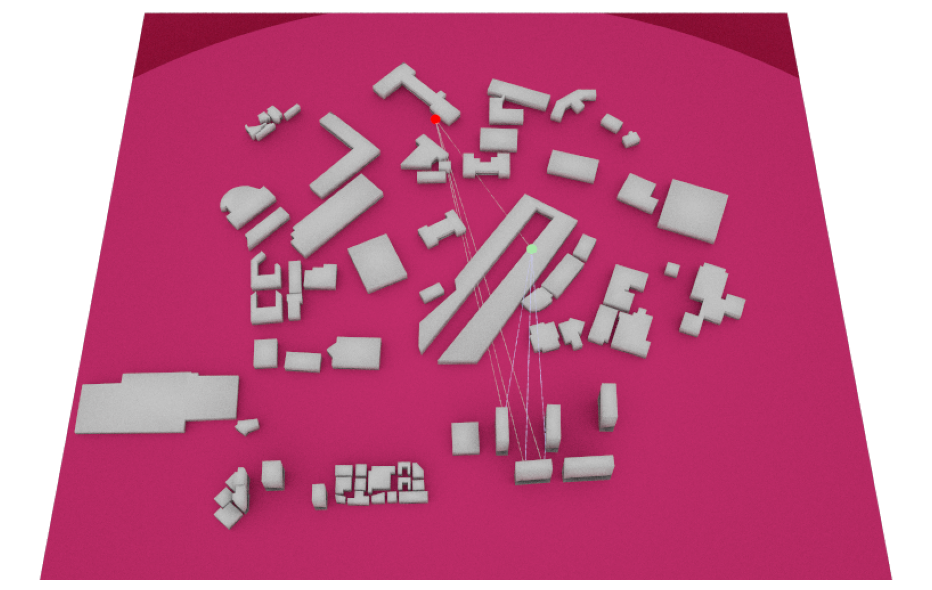

In [11]:
scene.render(camera=cam, paths=paths, num_samples=128, resolution=[800, 500]);

### 2.1 Generate the Coverage Map

In [12]:
rm_solver = RadioMapSolver()
rm = rm_solver(scene, max_depth=5, cell_size=(5.0, 5.0), samples_per_tx=int(2e5))

scene.render_to_file(camera=cam, radio_map=rm, filename="coverage.png", num_samples=128, resolution=[800, 500])

Bitmap[
  pixel_format = rgba,
  component_format = uint8,
  size = [800, 500],
  srgb_gamma = 1,
  struct = Struct<4>[
    uint8 R; // @0, normalized, gamma, premultiplied alpha
    uint8 G; // @1, normalized, gamma, premultiplied alpha
    uint8 B; // @2, normalized, gamma, premultiplied alpha
    uint8 A; // @3, normalized, alpha
  ],
  data = [ 1.53 MiB of image data ]
]

RadioMapSolver computes path gain on a spatial grid across the entire scene.  
cell_size specifies the spatial resolution of one grid cell.  
samples_per_tx specifies the number of rays launched from the transmitter; more samples improve accuracy but increase runtime.  
Yellow/green indicates stronger received power, while cyan/blue indicates weaker received power. Power is stronger near Tx when line of sight is available.

### 2.2 Verify Geometry and Tx/Rx Placement

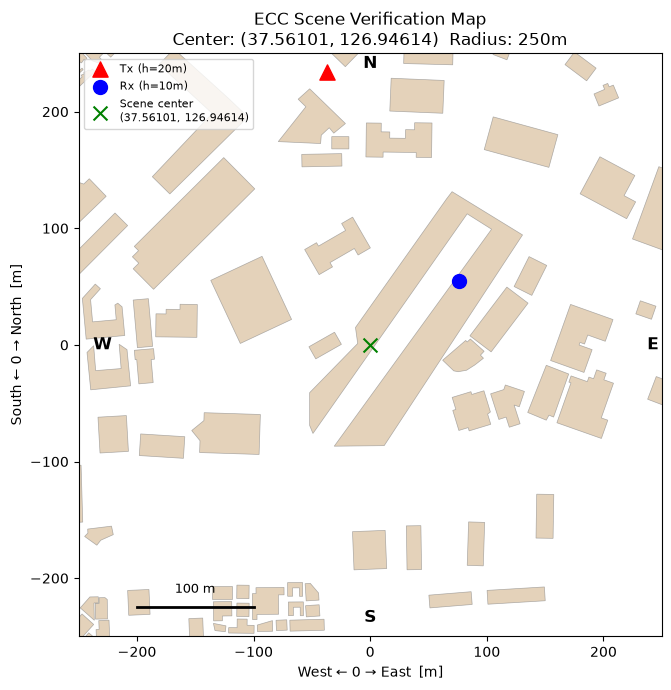

In [13]:
fig, ax = plt.subplots(figsize=(7, 7))

for _, row in gdf.iterrows():
    geom = row.geometry
    if geom is None or geom.geom_type != "Polygon":
        continue

    xy = [lonlat_to_xy(lon, lat) for lon, lat in geom.exterior.coords]
    poly = Polygon(xy)
    x, y = poly.exterior.xy
    ax.fill(x, y, facecolor="tan", edgecolor="gray", alpha=0.6, linewidth=0.5)

tx_x, tx_y = lonlat_to_xy(TX_LON, TX_LAT)
rx_x, rx_y = lonlat_to_xy(RX_LON, RX_LAT)

ax.scatter(tx_x, tx_y, c="red", marker="^", s=120, zorder=5,
           label=f"Tx (h={TX_HEIGHT}m)")
ax.scatter(rx_x, rx_y, c="blue", marker="o", s=100, zorder=5,
           label=f"Rx (h={RX_HEIGHT}m)")

ax.scatter(0, 0, c="green", marker="x", s=100, zorder=5,
           label=f"Scene center\n({LAT_CENTER}, {LON_CENTER})")

ax.set_xlim(-RADIUS_M, RADIUS_M)
ax.set_ylim(-RADIUS_M, RADIUS_M)
ax.set_aspect("equal")
ax.set_xlabel("West ← 0 → East  [m]")
ax.set_ylabel("South ← 0 → North  [m]")
ax.set_title(f"ECC Scene Verification Map\n"
             f"Center: ({LAT_CENTER}, {LON_CENTER})  Radius: {RADIUS_M}m")

ax.text(0, RADIUS_M*0.95, "N", ha="center", fontsize=12, fontweight="bold")
ax.text(0, -RADIUS_M*0.95, "S", ha="center", fontsize=12, fontweight="bold")
ax.text(RADIUS_M*0.95, 0, "E", va="center", fontsize=12, fontweight="bold")
ax.text(-RADIUS_M*0.95, 0, "W", va="center", fontsize=12, fontweight="bold")

ax.plot([-RADIUS_M*0.8, -RADIUS_M*0.8+100], [-RADIUS_M*0.9]*2,
        color="black", linewidth=2)
ax.text(-RADIUS_M*0.8+50, -RADIUS_M*0.85, "100 m", ha="center", fontsize=9)

ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig("ecc_scene/scene_verification_map.png", dpi=150)
plt.show()

## 3. Ray-traced channel response

In [14]:
a, tau = paths.cir(out_type="numpy")
# a(amplitude) shape: (num_rx, num_rx_ant, num_tx, num_tx_ant, num_paths, num_time_steps)
# tau(delay) shape: (num_rx, num_tx, num_paths)

a_cplx = a[0,0,0,0,:,0]
tau_s = tau[0, 0, :]      # Path delays in seconds
tau_ns = tau_s * 1e9      # Nanoseconds, used for plotting

print(f"Paths found : {len(a_cplx)}")
print(f"Delay spread : {tau_ns.max()-tau_ns.min():.1f}ns")

Paths found : 4
Delay spread : 1720.9ns


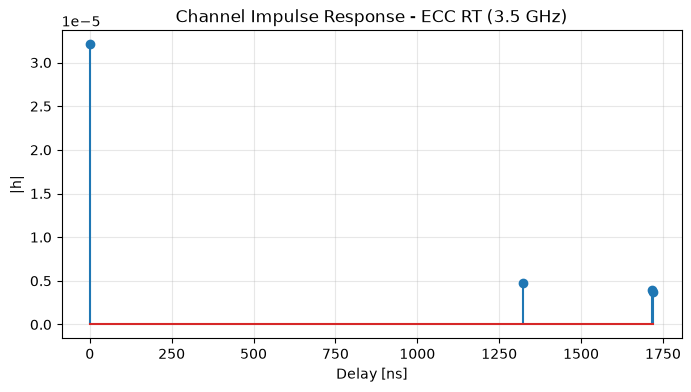

In [15]:
plt.figure(figsize=(8, 4))
plt.stem(tau_ns, np.abs(a_cplx))
plt.xlabel("Delay [ns]")
plt.ylabel("|h|")
plt.title("Channel Impulse Response - ECC RT (3.5 GHz)")
plt.grid(True, alpha=0.3)
plt.show()

paths.cir() converts the PathSolver result into a channel impulse response (CIR).  
A CIR consists of the complex amplitude and delay of each path. Delays are normalized relative to the first arriving path; later paths arrive after reflections or other interactions.

### 3.1 OFDM Channel Frequency Response H(f)

In [16]:
N_FFT = 64
SCS = 30e3

f_k = np.fft.fftfreq(N_FFT, d=1.0/(N_FFT*SCS))

# Convert the multipath CIR into an OFDM frequency response for each subcarrier.
# H[k] = Σ a_l · exp(-j2π f_k τ_l)
H_rt = np.sum(
    a_cplx[:, None] * np.exp(-1j * 2 * np.pi * tau_s[:, None] * f_k[None, :]),
    axis=0,
)

# Normalize average channel power to isolate frequency-selective fading in BER comparisons.
H_rt /= np.sqrt(np.mean(np.abs(H_rt)**2)) 

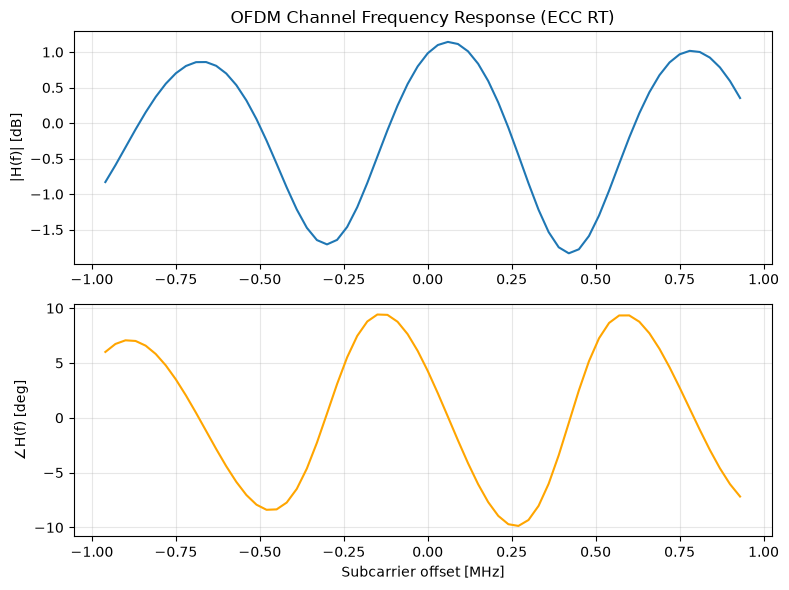

In [17]:
f_k_plot = np.fft.fftshift(f_k)
H_rt_plot = np.fft.fftshift(H_rt)

fig, axes = plt.subplots(2, 1, figsize=(8, 6))

axes[0].plot(f_k_plot/1e6, 20*np.log10(np.abs(H_rt_plot)))
axes[0].set_ylabel("|H(f)| [dB]")
axes[0].set_title("OFDM Channel Frequency Response (ECC RT)")
axes[0].grid(True, alpha=0.3)

axes[1].plot(f_k_plot/1e6, np.angle(H_rt_plot, deg=True), color="orange")
axes[1].set_xlabel("Subcarrier offset [MHz]")
axes[1].set_ylabel("∠H(f) [deg]")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 4. OFDM-QPSK Link Simulation
Transmitter: Repetition Coding → QPSK → OFDM Modulation

In [18]:
# Map pairs of bits to unit-energy QPSK symbols.
def qpsk_map(bits):

    # b0,b1 → (1-2b0)/√2 + j(1-2b1)/√2
    b0 = bits[0::2]
    b1 = bits[1::2]
    R = (1 - 2*b0) / np.sqrt(2)
    I = (1 - 2*b1) / np.sqrt(2)
    return R + 1j*I

N_SYM = 14
N_CP = 8
REP = 3

BITS_CODED = N_SYM*N_FFT*2

## 5. BER Results and Interpretation

BER is estimated through repeated simulations over an $E_b/N_0$ range of -4 to 12 dB.

- Black dashed line: theoretical uncoded QPSK BER in AWGN
- Blue: uncoded QPSK AWGN simulation
- Orange: Rep-3 QPSK AWGN simulation
- Green: Rep-3 QPSK simulation over the ECC ray-tracing channel

If the blue simulation result follows the black theoretical curve, the AWGN implementation is behaving as expected. The ECC ray-tracing channel captures multipath and frequency-selective fading from buildings and the ground, so its BER can be higher than that of a simple AWGN channel.

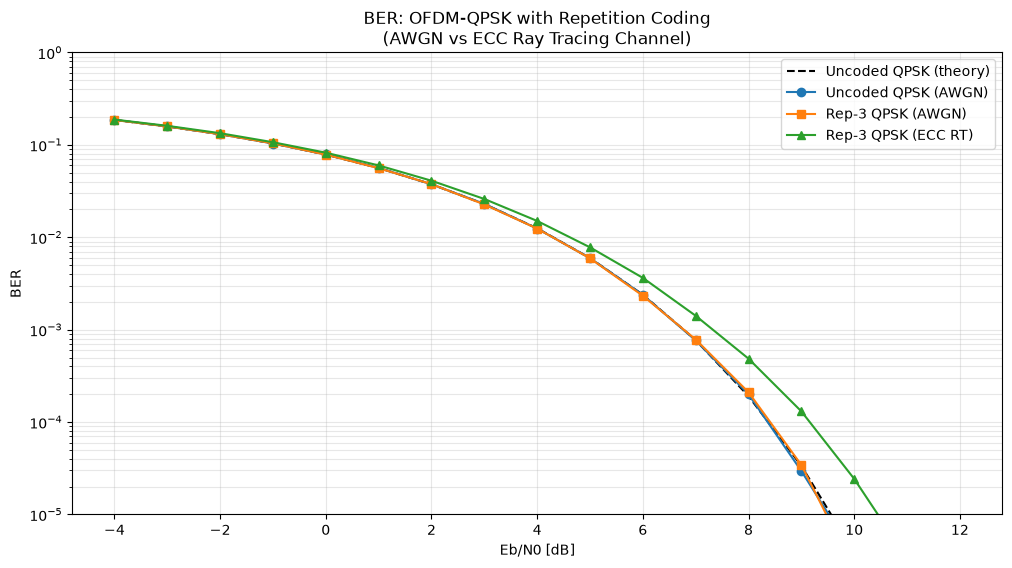

In [19]:
def ber_theory_qpsk(ebn0_db):
    ebn0 = 10**(ebn0_db/10)
    return 0.5 * erfc(np.sqrt(ebn0))


def run_trial(EbN0_dB, H_channel, REP, coded=True):
    rate = 1/REP if coded else 1.0
    bits_per_symbol = 2
    EbN0 = 10**(EbN0_dB/10)
    N0 = 1/(EbN0 * rate * bits_per_symbol)
    std = np.sqrt(N0/2)

    n_info_local = BITS_CODED if not coded else BITS_CODED // REP
    b_info_local = np.random.randint(0, 2, n_info_local)
    b_tx_local = np.repeat(b_info_local, REP) if coded else b_info_local

    b_pad_local = np.zeros(BITS_CODED, dtype=int)
    b_pad_local[:len(b_tx_local)] = b_tx_local
    s_tx_local = qpsk_map(b_pad_local)

    S_grid_local = s_tx_local.reshape(N_SYM, N_FFT)
    s_time_local = np.fft.ifft(S_grid_local, axis=-1)
    s_cp_local = np.hstack([s_time_local[:, -N_CP:], s_time_local])

    R_fft_local = np.fft.fft(s_cp_local[:, N_CP:], axis=-1)
    noise = std * (np.random.randn(*R_fft_local.shape) + 1j*np.random.randn(*R_fft_local.shape))
    R_grid_local = R_fft_local * H_channel[None, :] + noise
    Y_eq_local = R_grid_local / (H_channel[None, :] + 1e-10)

    llr_full_local = np.stack([Y_eq_local.real, Y_eq_local.imag], axis=-1).reshape(-1)

    if coded:
        n_coded_eff_local = (BITS_CODED // REP) * REP
        llr_eff_local = llr_full_local[:n_coded_eff_local]
        n = len(llr_eff_local) // REP
        llr_sum = llr_eff_local.reshape(n, REP).sum(axis=-1)
        b_rx_local = (llr_sum < 0).astype(int)
        ber = np.sum(b_rx_local != b_info_local) / n_info_local
    else:
        b_rx_local = (llr_full_local < 0).astype(int)
        ber = np.sum(b_rx_local != b_pad_local) / BITS_CODED

    return ber

# Evaluate BER across the Eb/N0 range.
ebn0_range = np.arange(-4, 13, 1)
n_trials = 2000


H_awgn = np.ones(N_FFT, dtype=complex)

ber_uncoded_awgn = []
ber_rep3_awgn = []
ber_rep3_rt = []

for ebn0_db in ebn0_range:
    b1 = np.mean([run_trial(ebn0_db, H_awgn, REP=1, coded=False) for _ in range(n_trials)])
    b2 = np.mean([run_trial(ebn0_db, H_awgn, REP=3, coded=True)  for _ in range(n_trials)])
    b3 = np.mean([run_trial(ebn0_db, H_rt,   REP=3, coded=True)  for _ in range(n_trials)])
    ber_uncoded_awgn.append(b1)
    ber_rep3_awgn.append(b2)
    ber_rep3_rt.append(b3)


plt.figure(figsize=(12,6))
plt.semilogy(ebn0_range, ber_theory_qpsk(ebn0_range), 'k--', label="Uncoded QPSK (theory)")
plt.semilogy(ebn0_range, ber_uncoded_awgn, 'o-', label="Uncoded QPSK (AWGN)")
plt.semilogy(ebn0_range, ber_rep3_awgn,    's-', label="Rep-3 QPSK (AWGN)")
plt.semilogy(ebn0_range, ber_rep3_rt,      '^-', label="Rep-3 QPSK (ECC RT)")
plt.xlabel("Eb/N0 [dB]")
plt.ylabel("BER")
plt.title("BER: OFDM-QPSK with Repetition Coding\n(AWGN vs ECC Ray Tracing Channel)")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.ylim(1e-5, 1)
plt.show()
